<a href="https://colab.research.google.com/github/udlbook/udlbook/blob/main/Notebooks/Chap10/10_5_Convolution_For_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Notebook 10.5: Convolution for MNIST**

This notebook builds a proper network for 2D convolution.  It works with the MNIST dataset (figure 15.15a), which was the original classic dataset for classifying images.  The network will take a 28x28 grayscale image and classify it into one of 10 classes representing a digit.

The code is adapted from https://nextjournal.com/gkoehler/pytorch-mnist

Work through the cells below, running each cell in turn. In various places you will see the words "TODO". Follow the instructions at these places and make predictions about what is going to happen or write code to complete the functions.

If you are using Google Colab, you can change your runtime to an instance with GPU support to speed up training, e.g. a T4 GPU. If you do this, the cell below should output ``device(type='cuda')``

Contact me at udlbookmail@gmail.com if you find any mistakes or have any suggestions.


In [22]:
import torch
import torchvision
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import random
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [23]:
# Run this once to load the train and test data straight into a dataloader class
# that will provide the batches

# (It may complain that some files are missing because the files seem to have been
# reorganized on the underlying website, but it still seems to work). If everything is working
# properly, then the whole notebook should run to the end without further problems
# even before you make changes.
batch_size_train = 64
batch_size_test = 1000

# TODO Change this directory to point towards an existing directory (No change needed if using Google Colab)
myDir = './data'

train_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST(myDir, train=True, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_train, shuffle=True)

test_loader = torch.utils.data.DataLoader(
  torchvision.datasets.MNIST(myDir, train=False, download=True,
                             transform=torchvision.transforms.Compose([
                               torchvision.transforms.ToTensor(),
                               torchvision.transforms.Normalize(
                                 (0.1307,), (0.3081,))
                             ])),
  batch_size=batch_size_test, shuffle=True)

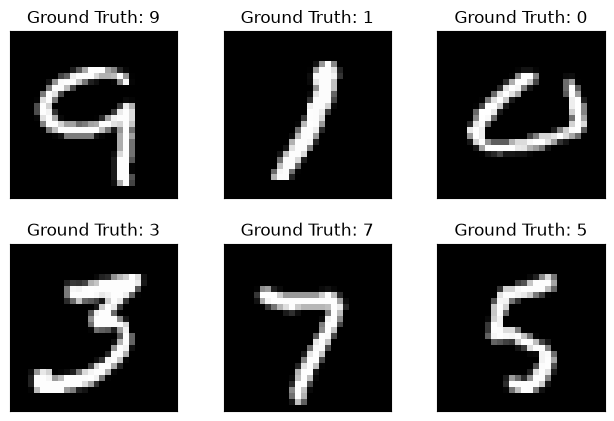

In [24]:
# Let's draw some of the training data
examples = enumerate(test_loader)
batch_idx, (example_data, example_targets) = next(examples)

fig = plt.figure()
for i in range(6):
  plt.subplot(2,3,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Ground Truth: {}".format(example_targets[i]))
  plt.xticks([])
  plt.yticks([])
plt.show()

Define the network.  This is a more typical way to define a network than the sequential structure.  We define a class for the network, and define the parameters in the constructor.  Then we use a function called forward to actually run the network.  It's easy to see how you might use residual connections in this format.

In [25]:
from os import X_OK
# TODO Change this class to implement
# 1. A valid convolution with kernel size 5, 1 input channel and 10 output channels
# 2. A max pooling operation over a 2x2 area
# 3. A Relu
# 4. A valid convolution with kernel size 5, 10 input channels and 20 output channels
# 5. A 2D Dropout layer
# 6. A max pooling operation over a 2x2 area
# 7. A relu
# 8. A flattening operation
# 9. A fully connected layer mapping from (whatever dimensions we are at-- find out using .shape) to 50
# 10. A ReLU
# 11. A fully connected layer mapping from 50 to 10 dimensions
# 12. A softmax function.

# Replace this class which implements a minimal network (which still does okay)
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        # Primera convolución: kernel 5x5, entra 1 canal, salen 10 canales
        self.conv1 = nn.Conv2d(1, 10, kernel_size=5)

        # Segunda convolución: kernel 5x5, entran 10 canales, salen 20 canales
        self.conv2 = nn.Conv2d(10, 20, kernel_size=5)

        # Capa Dropout 2D para apagar neuronas al azar y evitar sobreajuste
        self.conv2_drop = nn.Dropout2d()

        # Capa lineal: toma los 320 números aplanados y los reduce a 50
        self.fc1 = nn.Linear(320, 50)

        #  Capa final: de 50 números a los 10 dígitos posibles (0 al 9)
        self.fc2 = nn.Linear(50, 10)
        
    def forward(self, x):
        # Convolución 1 -> Max pooling 2x2 -> ReLU
        # (La imagen de 28x28 pasa a 24x24 por la conv, y luego a 12x12 por el pooling)
        x = self.conv1(x)
        x = F.max_pool2d(x, 2)
        x = F.relu(x)

        # Convolución 2 -> Dropout -> Max pooling 2x2 -> ReLU
        # (De 12x12 pasa a 8x8 por la conv, y luego a 4x4 por el pooling)
        x = self.conv2(x)
        x = self.conv2_drop(x)
        x = F.max_pool2d(x, 2)
        x = F.relu(x)

        # Aplanamos los 20 canales de 4x4 (20 x 4 x 4 = 320 números en fila)
        x = x.flatten(1)

        #  Primera capa lineal -> ReLU
        x = self.fc1(x)
        x = F.relu(x)

        # Capa lineal final -> Log Softmax para obtener las probabilidades
        x = self.fc2(x)
        return F.log_softmax(x, dim=1)





In [26]:
# He initialization of weights
def weights_init(layer_in):
  if isinstance(layer_in, nn.Linear):
    nn.init.kaiming_uniform_(layer_in.weight)
    layer_in.bias.data.fill_(0.0)

In [27]:
# Create network
model = Net().to(device)
# Initialize model weights
model.apply(weights_init)
# Define optimizer
optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.5)

In [28]:
# Main training routine
def train(epoch):
  model.train()
  # Get each
  for batch_idx, (data, target) in enumerate(train_loader):
    data = data.to(device)
    target = target.to(device)
    optimizer.zero_grad()
    output = model(data)
    loss = F.nll_loss(output, target)
    loss.backward()
    optimizer.step()
    # Store results
    if batch_idx % 10 == 0:
      print('Train Epoch: {} [{}/{}]\tLoss: {:.6f}'.format(
        epoch, batch_idx * len(data), len(train_loader.dataset), loss.item()))

In [29]:
# Run on test data
def test():
  model.eval()
  test_loss = 0
  correct = 0
  with torch.no_grad():
    for data, target in test_loader:
      data = data.to(device)
      target = target.to(device)
      output = model(data)
      test_loss += F.nll_loss(output, target, size_average=False).item()
      pred = output.data.max(1, keepdim=True)[1]
      correct += pred.eq(target.data.view_as(pred)).sum()
  test_loss /= len(test_loader.dataset)
  print('\nTest set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
    test_loss, correct, len(test_loader.dataset),
    100. * correct / len(test_loader.dataset)))

In [30]:
# Get initial performance
test()
# Train for three epochs
n_epochs = 3
for epoch in range(1, n_epochs + 1):
  train(epoch)
  test()


Test set: Avg. loss: 2.4521, Accuracy: 1119/10000 (11%)

Train Epoch: 1 [0/60000]	Loss: 2.591191
Train Epoch: 1 [640/60000]	Loss: 2.219257
Train Epoch: 1 [1280/60000]	Loss: 2.104882
Train Epoch: 1 [1920/60000]	Loss: 1.913260
Train Epoch: 1 [2560/60000]	Loss: 1.994519
Train Epoch: 1 [3200/60000]	Loss: 1.621130
Train Epoch: 1 [3840/60000]	Loss: 1.373894
Train Epoch: 1 [4480/60000]	Loss: 1.213472
Train Epoch: 1 [5120/60000]	Loss: 1.120969
Train Epoch: 1 [5760/60000]	Loss: 1.030746
Train Epoch: 1 [6400/60000]	Loss: 0.856468
Train Epoch: 1 [7040/60000]	Loss: 1.112357
Train Epoch: 1 [7680/60000]	Loss: 0.779405
Train Epoch: 1 [8320/60000]	Loss: 0.921581
Train Epoch: 1 [8960/60000]	Loss: 0.595631
Train Epoch: 1 [9600/60000]	Loss: 0.531864
Train Epoch: 1 [10240/60000]	Loss: 0.620160
Train Epoch: 1 [10880/60000]	Loss: 0.495411
Train Epoch: 1 [11520/60000]	Loss: 0.436914
Train Epoch: 1 [12160/60000]	Loss: 0.492594
Train Epoch: 1 [12800/60000]	Loss: 0.703399
Train Epoch: 1 [13440/60000]	Loss: 0.5

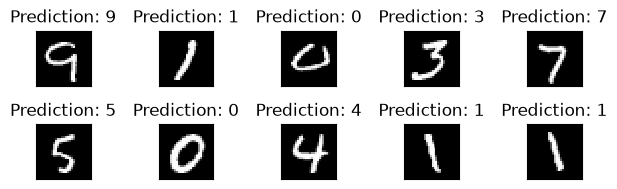

In [32]:
# Run network on data we got before and show predictions
# Le agregamos .to(device) para que esté en el mismo lugar que el modelo
output = model(example_data.to(device))

fig = plt.figure()
for i in range(10):
  plt.subplot(5,5,i+1)
  plt.tight_layout()
  plt.imshow(example_data[i][0], cmap='gray', interpolation='none')
  plt.title("Prediction: {}".format(
    output.data.max(1, keepdim=True)[1][i].item()))
  plt.xticks([])
  plt.yticks([])
plt.show()


### Resumen de lo visto

En este último cuaderno cerramos todo el recorrido del capítulo construyendo una red convolucional completa para clasificar el conjunto de datos MNIST, que contiene miles de imágenes en blanco y negro de números escritos a mano del 0 al 9. Mientras que una red tradicional totalmente conectada tendría que mirar cada uno de los 784 píxeles por separado sin entender la geometría de la imagen, la red convolucional aprovecha la cercanía entre píxeles deslizando pequeños filtros capaces de identificar patrones básicos como bordes, esquinas y las curvas típicas de cada dígito.

A lo largo de la red, los datos atraviesan un flujo por etapas cuidadosamente diseñado. Primero, una convolución busca diez tipos de trazos visuales y un max-pooling reduce la imagen a la mitad. Luego, una segunda convolución combina esos trazos para encontrar patrones más complejos en veinte canales distintos, seguida de una capa de dropout que apaga partes de la red al azar durante el entrenamiento para evitar que memorice los dibujos y lograr que reconozca la caligrafía de cualquier persona. Finalmente, un segundo max-pooling reduce el tamaño hasta dejarnos con un resumen compacto de apenas 320 números, los cuales son evaluados por dos capas lineales para decidir qué número aparece en la foto.

Este ejercicio conecta de forma definitiva todo lo que trabajamos a lo largo de los cuadernos: desde programar a mano operaciones en una y dos dimensiones con matrices y ceros de relleno, pasando por las técnicas para achicar y agrandar imágenes, hasta llegar a una arquitectura moderna y profesional en PyTorch. Al entrenar el modelo por tan solo tres pasadas, comprobamos que supera con facilidad el 98% de acierto, demostrando con resultados reales por qué las capas convolucionales son la herramienta fundamental para trabajar con imágenes.
